# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [20]:
ROLL_NO = 1024170167          # <-- your full roll number
NAME = "Harshita Rao"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [21]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [22]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [23]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170167   Name: Harshita Rao   Fingerprint: 5BD183F5   Tickets: 14

Ticket_ID                                                                                    Ticket_Text
      T01                                           The WiFi crashes while opening. It worked yesterday.
      T02                          I couldn't connect to the printer during the lab. Can you check this?
      T03                                                      The printer won't print; it isn't jammed.
      T04                        Matlab is showing an error since yesterday. I have tried several times!
      T05                                                 Re-installing didn't help; log-in still fails!
      T06                          Email failed to open after restarting the system. Can you check this?
      T07                                                     The VPN failed to open. Please resolve it.
      T08 I keep getting logged out of the printer when I use mobile hotspot

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [24]:
# Your code

import inspect
print(inspect.getsource(process_ticket))


def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}



In [25]:

import pandas as pd

results = []

for _, row in df.iterrows():
    processed = process_ticket(row["Ticket_Text"])

    results.append({
        "Ticket_ID": row["Ticket_ID"],
        "Number of Sentences": len(processed["sentences"]),
        "Number of Tokens": len(processed["tokens"]),
        "Punctuation Tokens": len(processed["punct"]),
        "Stopwords": len(processed["stops"]),
        "Unique Tokens": len(set(processed["tokens"])),
        "Final Tokens": len(processed["final"])
    })


q1_table = pd.DataFrame(results)


display(q1_table)


total_row = {
    "Ticket_ID": "TOTAL",
    "Number of Sentences": q1_table["Number of Sentences"].sum(),
    "Number of Tokens": q1_table["Number of Tokens"].sum(),
    "Punctuation Tokens": q1_table["Punctuation Tokens"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique Tokens": None,
    "Final Tokens": q1_table["Final Tokens"].sum()
}

q1_with_total = pd.concat(
    [q1_table, pd.DataFrame([total_row])],
    ignore_index=True
)

print("Preprocessing table with totals:")
display(q1_with_total)


,Ticket_ID,Number of Sentences,Number of Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,10,2,3,9,5
1,T02,2,16,2,8,15,6
2,T03,1,11,2,3,10,6
3,T04,2,14,2,4,14,8
4,T05,1,9,2,1,9,6
5,T06,2,14,2,6,14,6
6,T07,2,10,2,3,9,5
7,T08,2,21,2,9,18,10
8,T09,2,17,2,7,16,8
9,T10,2,16,2,7,15,7


Preprocessing table with totals:


,Ticket_ID,Number of Sentences,Number of Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,10,2,3,9,5
1,T02,2,16,2,8,15,6
2,T03,1,11,2,3,10,6
3,T04,2,14,2,4,14,8
4,T05,1,9,2,1,9,6
5,T06,2,14,2,6,14,6
6,T07,2,10,2,3,9,5
7,T08,2,21,2,9,18,10
8,T09,2,17,2,7,16,8
9,T10,2,16,2,7,15,7


In [26]:
display(q1_with_total.tail(1))

,Ticket_ID,Number of Sentences,Number of Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
14,TOTAL,24,188,27,69,None,92


In [27]:

ticket = df.iloc[0]
processed = process_ticket(ticket["Ticket_Text"])

print("Ticket ID:", ticket["Ticket_ID"])
print("\nOriginal text:", ticket["Ticket_Text"])
print("\nActual tokens:", processed["tokens"])
print("\nPunctuation tokens:", processed["punct"])
print("\nStopwords:", processed["stops"])
print("\nFinal tokens:", processed["final"])


Ticket ID: T01

Original text: The WiFi crashes while opening. It worked yesterday.

Actual tokens: ['the', 'wifi', 'crashes', 'while', 'opening', '.', 'it', 'worked', 'yesterday', '.']

Punctuation tokens: ['.', '.']

Stopwords: ['the', 'while', 'it']

Final tokens: ['wifi', 'crashes', 'opening', 'worked', 'yesterday']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Some final tokens, such as “n't”, “'s”, and “ca”, are not complete words. They originate from contractions such as isn't, it's, and can't. The tokenizer splits these contractions into separate tokens, and the preprocessing function removes punctuation and stopwords without recombining the fragments. As a result, these fragments may remain in the final tokens.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [28]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

import re

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = r"https?://[^\s]+|www\.[^\s]+"

phone_pattern = r"(?<!\w)(?:\+?\d{1,3}[-.\s]?)?(?:\(?\d{3,5}\)?[-.\s]?)\d{5,8}(?!\w)"

def redact_text(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("Replacement patterns created successfully.")


Replacement patterns created successfully.


In [29]:

for _, row in df.iterrows():
    original = row["Ticket_Text"]
    cleaned = redact_text(original)

    if cleaned != original:
        print(f"\n{row['Ticket_ID']}")
        print("Original:", original)
        print("Replaced:", cleaned)



T12
Original: Email me at helpdesk@university.edu.
Replaced: Email me at <EMAIL>.


In [30]:

for line in TEST_LINES:
    print("Original:", line)
    print("Replaced:", redact_text(line))
    print("-" * 60)


Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Replaced: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
------------------------------------------------------------
Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Replaced: Call <PHONE>, <PHONE> or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
------------------------------------------------------------
Original: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Replaced: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
------------------------------------------------------------


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* The exact number depends on your 14 generated tickets. Run this cell to obtain the count of capitalized words that appear at the beginning of sentences. Note that this counts sentence-initial occurrences, so a word that is capitalized for another reason may also appear in the list.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [31]:
# Your code

from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r"""https?://[^\s]+|www\.[^\s]+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|\+?\d[\d().\-\s]{7,}\d|\d+(?:\.\d+)+|\b[A-Za-z]+(?:-[A-Za-z]+)+\b|\b[A-Za-z]+(?:'[A-Za-z]+)?\b|\d+|[^\w\s]"""

my_tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

print("Custom tokenizer created successfully.")


Custom tokenizer created successfully.


In [32]:

for line in TEST_LINES:
    print("Original:", line)
    print("My tokenizer:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))
    print("-" * 70)


Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
My tokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
----------------------------------------------------------------------
Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
My tokenizer: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
----

In [33]:

for _, row in df.iterrows():
    text = row["Ticket_Text"]

    print(f"\n{row['Ticket_ID']}: {text}")
    print("My tokenizer:", my_tokenize(text))
    print("word_tokenize:", word_tokenize(text))



T01: The WiFi crashes while opening. It worked yesterday.
My tokenizer: ['The', 'WiFi', 'crashes', 'while', 'opening', '.', 'It', 'worked', 'yesterday', '.']
word_tokenize: ['The', 'WiFi', 'crashes', 'while', 'opening', '.', 'It', 'worked', 'yesterday', '.']

T02: I couldn't connect to the printer during the lab. Can you check this?
My tokenizer: ['I', "couldn't", 'connect', 'to', 'the', 'printer', 'during', 'the', 'lab', '.', 'Can', 'you', 'check', 'this', '?']
word_tokenize: ['I', 'could', "n't", 'connect', 'to', 'the', 'printer', 'during', 'the', 'lab', '.', 'Can', 'you', 'check', 'this', '?']

T03: The printer won't print; it isn't jammed.
My tokenizer: ['The', 'printer', "won't", 'print', ';', 'it', "isn't", 'jammed', '.']
word_tokenize: ['The', 'printer', 'wo', "n't", 'print', ';', 'it', 'is', "n't", 'jammed', '.']

T04: Matlab is showing an error since yesterday. I have tried several times!
My tokenizer: ['Matlab', 'is', 'showing', 'an', 'error', 'since', 'yesterday', '.', 'I',

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [35]:
# Your code
all_final_tokens = []

for text in df["Ticket_Text"]:
    processed = process_ticket(text)
    all_final_tokens.extend(processed["final"])

unique_final_tokens = sorted(set(all_final_tokens))

print("Total final tokens:", len(all_final_tokens))
print("Unique final tokens:", len(unique_final_tokens))
print(unique_final_tokens)


Total final tokens: 92
Unique final tokens: 68
['2', '3.5', '30', 'another', 'boot', 'campus', 'changed', 'check', 'connect', 'connected', 'could', 'crashes', 'email', 'error', 'failed', 'fails', 'file', 'getting', 'help', 'helpdesk', 'hotspot', 'hours', 'jammed', 'keep', 'know', 'lab', 'log-in', 'logged', 'matlab', 'mobile', "n't", 'occurs', 'open', 'opening', 'pcs', 'please', 'portal', 'print', 'printer', 'problem', 'projector', 'python', 're-installing', 'resolve', 'restarting', 'running', 'several', 'showing', 'since', 'slowly', 'solution', 'still', 'student', 'system', 'times', 'tried', 'unable', 'university.edu', 'uploading', 'urgent', 'use', 'vpn', 'wi-fi', 'wifi', 'wo', 'worked', 'working', 'yesterday']


In [36]:

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()

regexp_stemmer = RegexpStemmer(r"ing$|ed$|s$", min=3)

lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    return "n"

tagged_tokens = pos_tag(unique_final_tokens)

pos_map = {
    word: get_wordnet_pos(tag)
    for word, tag in tagged_tokens
}

comparison = []

for word in unique_final_tokens:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp_stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, pos=pos_map[word])

    if len({p, l, r, lemma}) > 1:
        comparison.append({
            "Original Word": word,
            "Porter": p,
            "Lancaster": l,
            "Regexp": r,
            "WordNet Lemma": lemma
        })

q4_table = pd.DataFrame(comparison)

print("Words with differing outputs:")
display(q4_table)


Words with differing outputs:


,Original Word,Porter,Lancaster,Regexp,WordNet Lemma
0,another,anoth,anoth,another,another
1,campus,campu,camp,campu,campus
2,changed,chang,chang,chang,change
3,crashes,crash,crash,crashe,crash
4,error,error,er,error,error
5,fails,fail,fail,fail,fails
6,file,file,fil,file,file
7,getting,get,get,gett,get
8,jammed,jam,jam,jamm,jam
9,logged,log,log,logg,log


In [37]:

suffix_examples = {
    "ing": [w for w in unique_final_tokens if w.endswith("ing")],
    "ed": [w for w in unique_final_tokens if w.endswith("ed")],
    "s": [w for w in unique_final_tokens if w.endswith("s")]
}

for suffix, words in suffix_examples.items():
    print(f"Words ending in '{suffix}':", words)


Words ending in 'ing': ['getting', 'opening', 're-installing', 'restarting', 'running', 'showing', 'uploading', 'working']
Words ending in 'ed': ['changed', 'connected', 'failed', 'jammed', 'logged', 'tried', 'worked']
Words ending in 's': ['campus', 'crashes', 'fails', 'hours', 'occurs', 'pcs', 'times']


In [38]:
import nltk
nltk.download("averaged_perceptron_tagger_eng")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming: The Regexp Stemmer may convert “crashes” to “crashe” by removing only the final “s”, producing an invalid word.

Under-stemming: If “crashes” and “crashed” remain as different stems under a stemming method, related word forms have not been reduced to a common stem.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

In [39]:
# Your code

from nltk.stem import PorterStemmer
from nltk.util import bigrams
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

porter = PorterStemmer()

S1 = []
S2 = []
S3 = []

for text in df["Ticket_Text"]:
    processed = process_ticket(text)

    S1.extend(processed["tokens"])
    S2.extend([
        token for token in processed["tokens"]
        if token not in processed["punct"]
    ])
    S3.extend(processed["final"])

S4 = [porter.stem(token) for token in S3]

print("Corpus sizes:", len(S1), len(S2), len(S3), len(S4))


Corpus sizes: 188 161 92 92


In [40]:

corpora = {
    "S1 - All tokens": S1,
    "S2 - Without punctuation": S2,
    "S3 - Final tokens": S3,
    "S4 - Porter stemming": S4
}

stats = []

for name, corpus in corpora.items():
    total = len(corpus)
    unique = len(set(corpus))
    ttr = unique / total if total else 0

    stats.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

q5_stats = pd.DataFrame(stats)
display(q5_stats)


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 - All tokens,188,100,0.5319
1,S2 - Without punctuation,161,95,0.5901
2,S3 - Final tokens,92,68,0.7391
3,S4 - Porter stemming,92,64,0.6957


In [41]:

print("Top 10 words in S1:")
display(pd.DataFrame(
    Counter(S1).most_common(10),
    columns=["Word", "Frequency"]
))

print("Top 10 words in S3:")
display(pd.DataFrame(
    Counter(S3).most_common(10),
    columns=["Word", "Frequency"]
))


Top 10 words in S1:


,Word,Frequency
0,.,18
1,the,11
2,i,9
3,is,7
4,n't,6
5,to,6
6,?,4
7,when,4
8,use,4
9,it,3


Top 10 words in S3:


,Word,Frequency
0,n't,6
1,use,4
2,printer,3
3,mobile,3
4,hotspot,3
5,yesterday,2
6,could,2
7,connect,2
8,check,2
9,email,2


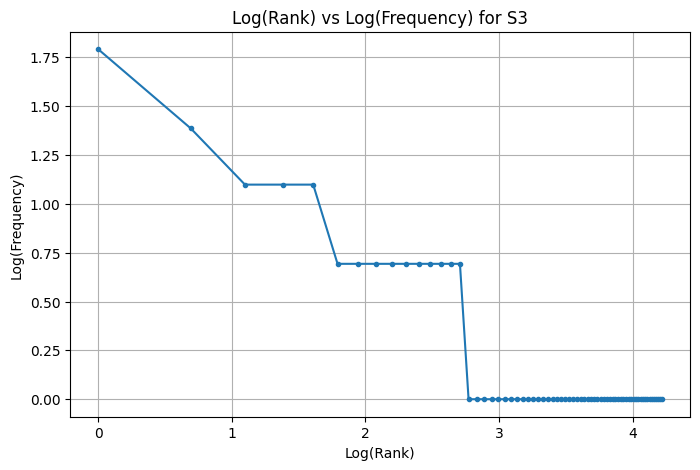

In [42]:

frequency_counts = Counter(S3).most_common()
ranks = np.arange(1, len(frequency_counts) + 1)
frequencies = np.array([freq for word, freq in frequency_counts])

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(frequencies), marker=".")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()


In [43]:

print("Top 5 bigrams in S1:")
display(pd.DataFrame(
    Counter(bigrams(S1)).most_common(5),
    columns=["Bigram", "Frequency"]
))

print("Top 5 bigrams in S3:")
display(pd.DataFrame(
    Counter(bigrams(S3)).most_common(5),
    columns=["Bigram", "Frequency"]
))


Top 5 bigrams in S1:


,Bigram,Frequency
0,"(., i)",6
1,"(the, printer)",3
2,"(when, i)",3
3,"(i, use)",3
4,"(use, mobile)",3


Top 5 bigrams in S3:


,Bigram,Frequency
0,"(use, mobile)",3
1,"(mobile, hotspot)",3
2,"(could, n't)",2
3,"(n't, connect)",2
4,"(failed, open)",2


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR changes because preprocessing removes punctuation and stopwords, while Porter stemming reduces related word forms to common stems. Removing tokens can change the proportion of unique words, and stemming often reduces the number of distinct word types.